# Bloc 3 — Notebook 1 : Machine Learning
## Analyse prédictive des prix des montres de luxe

**Auteurs du mini-projet :** Ronny Douglas, Victorien Alleg — MSc 2025-2026, Eugenia School  
**Cours :** Machine Learning & Deep Learning (Georgina)

**Objectif.** Comprendre les facteurs qui déterminent le prix d'une montre de luxe et construire deux modèles :
1. une **régression** qui prédit le prix (USD) ;
2. une **classification** qui range une montre en *Accessible* (< 8 400 \$) ou *Premium* (≥ 8 400 \$).

**Données.** *Luxury Watch Prices* (Kaggle) : 507 montres, 14 variables (marque, modèle, matériaux, mouvement, étanchéité, dimensions, complications, réserve de marche, prix).

## 1. Chargement et nettoyage
Le prix est stocké en texte (`"9,500"`) : on le convertit en nombre. Une ligne sans prix est retirée. Les valeurs manquantes de *Complications* (122) et *Power Reserve* (14) sont des absences réelles : on les code comme catégorie (`None` / `Unknown`) plutôt que de les supprimer.

In [1]:
import re, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42
np.random.seed(SEED)

df = pd.read_csv("data/luxury_watch.csv", encoding="utf-8-sig")
df["Price (USD)"] = pd.to_numeric(df["Price (USD)"].astype(str).str.replace(",", ""), errors="coerce")
df = df.dropna(subset=["Price (USD)"]).reset_index(drop=True)
df["Complications"] = df["Complications"].fillna("None")
df["Power Reserve"] = df["Power Reserve"].fillna("Unknown")
NUM = ["Case Diameter (mm)", "Case Thickness (mm)", "Band Width (mm)"]
CAT = ["Brand", "Model", "Case Material", "Strap Material", "Movement Type", "Water Resistance",
       "Dial Color", "Crystal Material", "Complications", "Power Reserve"]
TARGET = "Price (USD)"
SEUIL = 8400  # médiane arrondie : frontière Accessible / Premium
df["Premium"] = (df[TARGET] >= SEUIL).astype(int)
print(df.shape)

(506, 15)


In [2]:
df.head()

,Brand,Model,Case Material,Strap Material,Movement Type,Water Resistance,Case Diameter (mm),Case Thickness (mm),Band Width (mm),Dial Color,Crystal Material,Complications,Power Reserve,Price (USD),Premium
0,Rolex,Submariner,Stainless Steel,Stainless Steel,Automatic,300 meters,40.0,13.00,20.0,Black,Sapphire,Date,48 hours,9500.0,1
1,Omega,Seamaster,Titanium,Rubber,Automatic,600 meters,43.5,14.47,21.0,Blue,Sapphire,Date,60 hours,5800.0,0
2,Tag Heuer,Carrera,Stainless Steel,Leather,Automatic,100 meters,41.0,13.00,20.0,White,Sapphire,Chronograph,42 hours,4200.0,0
3,Breitling,Navitimer,Stainless Steel,Stainless Steel,Automatic,30 meters,43.0,14.25,22.0,Black,Sapphire,Chronograph,70 hours,7900.0,0
4,Cartier,Tank Solo,Stainless Steel,Leather,Quartz,30 meters,31.0,6.05,20.0,Silver,Sapphire,None,Unknown,2800.0,0


In [3]:
df[NUM + [TARGET]].describe().round(1)

,Case Diameter (mm),Case Thickness (mm),Band Width (mm),Price (USD)
count,506.0,506.0,506.0,506.0
mean,41.0,11.6,21.1,12083.0
std,2.5,2.5,1.7,10419.8
min,27.5,5.0,15.0,495.0
25%,40.0,9.8,20.0,5500.0
50%,41.0,12.0,20.0,8350.0
75%,42.0,13.3,22.0,16450.0
max,46.5,17.5,28.0,70000.0


## 2. Analyse exploratoire
### 2.1 Distribution des prix

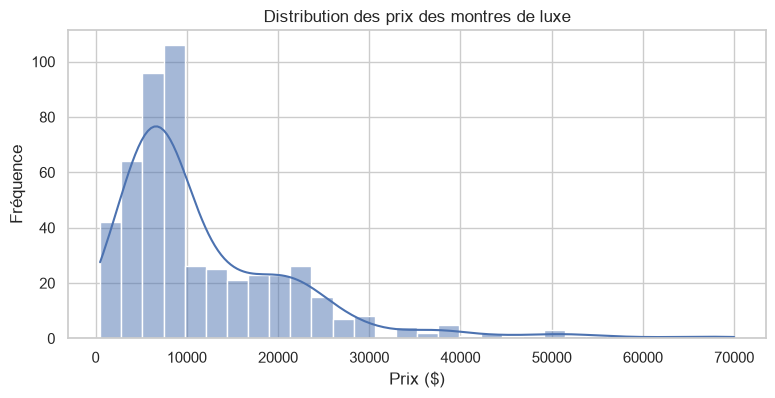

Médiane : 8,350 $  |  Moyenne : 12,083 $  |  Asymétrie : 2.15


In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(df[TARGET], bins=30, kde=True, ax=ax)
ax.set_title("Distribution des prix des montres de luxe"); ax.set_xlabel("Prix ($)"); ax.set_ylabel("Fréquence")
plt.savefig("figs/01_distribution_prix.png", dpi=150, bbox_inches="tight"); plt.show()
print(f"Médiane : {df[TARGET].median():,.0f} $  |  Moyenne : {df[TARGET].mean():,.0f} $  |  Asymétrie : {df[TARGET].skew():.2f}")

Forte asymétrie à droite : la majorité des montres se situe entre 5 000 et 15 000 \$, avec une longue traîne ultra-premium (jusqu'à 70 000 \$).

### 2.2 Prix moyen par marque

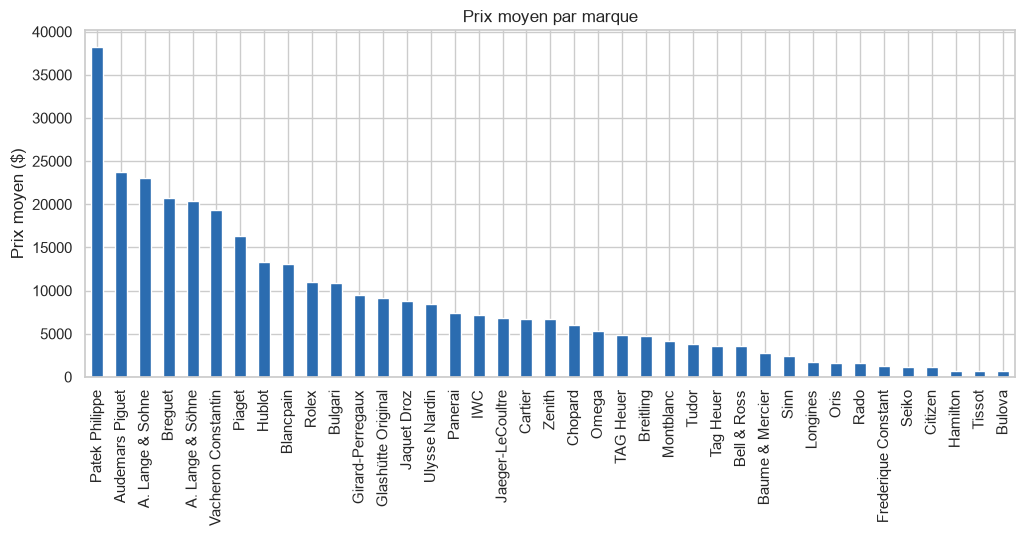

Brand
Patek Philippe      38233.0
Audemars Piguet     23734.0
A. Lange & Sohne    23000.0
Breguet             20696.0
A. Lange & Söhne    20400.0
Name: Price (USD), dtype: float64

In [5]:
pm = df.groupby("Brand")[TARGET].mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(12, 4.5))
pm.plot.bar(ax=ax, color="#2b6cb0")
ax.set_title("Prix moyen par marque"); ax.set_ylabel("Prix moyen ($)"); ax.set_xlabel("")
plt.savefig("figs/02_prix_marque.png", dpi=150, bbox_inches="tight"); plt.show()
pm.head(5).round(0)

### 2.3 Corrélations — variables numériques

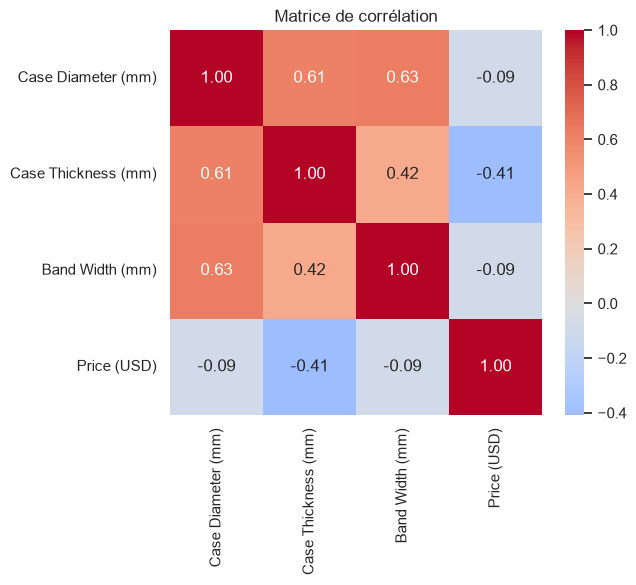

In [6]:
corr = df[NUM + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Matrice de corrélation")
plt.savefig("figs/03_correlation.png", dpi=150, bbox_inches="tight"); plt.show()

Les dimensions sont corrélées entre elles mais **négativement ou faiblement** avec le prix : dans le luxe, « plus grand » ne veut pas dire « plus cher ». L'épaisseur est la plus liée (négativement) : les montres haut de gamme privilégient la finesse.

### 2.4 Variables catégorielles — V de Cramér

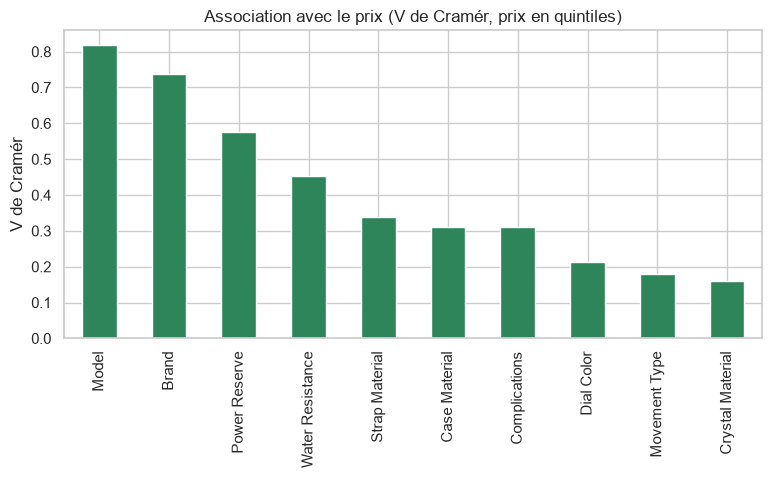

Model               0.82
Brand               0.74
Power Reserve       0.58
Water Resistance    0.45
Strap Material      0.34
Case Material       0.31
Complications       0.31
Dial Color          0.21
Movement Type       0.18
Crystal Material    0.16
dtype: float64

In [7]:
from scipy.stats import chi2_contingency
def cramers_v(x, y):
    t = pd.crosstab(x, y); chi2 = chi2_contingency(t)[0]; n = t.values.sum(); r, k = t.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))
price_bin = pd.qcut(df[TARGET], 5, labels=False)
cv = pd.Series({c: cramers_v(df[c], price_bin) for c in CAT}).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 4)); cv.plot.bar(ax=ax, color="#2f855a")
ax.set_title("Association avec le prix (V de Cramér, prix en quintiles)"); ax.set_ylabel("V de Cramér")
plt.savefig("figs/04_cramer.png", dpi=150, bbox_inches="tight"); plt.show(); cv.round(2)

### 2.5 Impact du matériau du boîtier

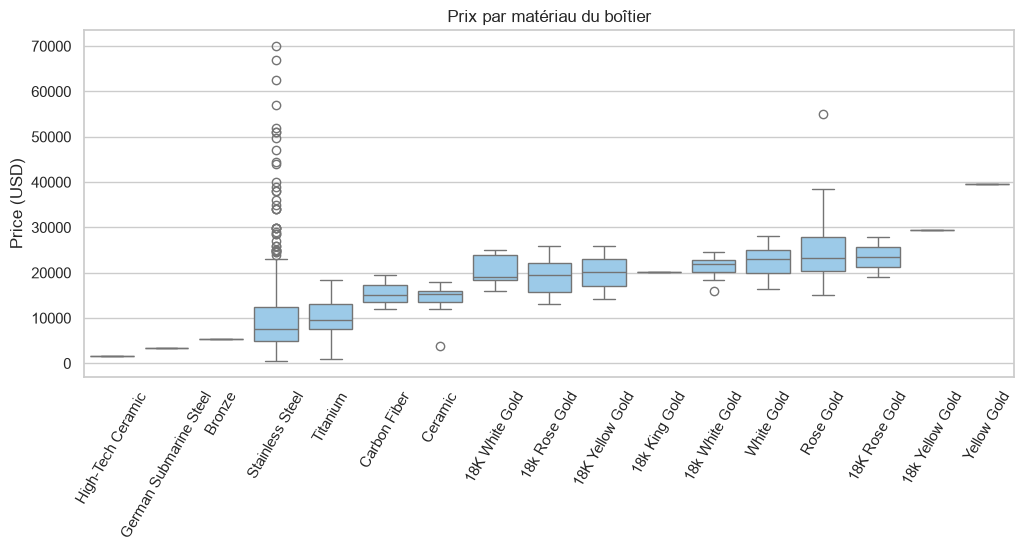

In [8]:
order = df.groupby("Case Material")[TARGET].median().sort_values().index
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.boxplot(data=df, x="Case Material", y=TARGET, order=order, ax=ax, color="#90cdf4")
ax.tick_params(axis="x", rotation=60); ax.set_title("Prix par matériau du boîtier"); ax.set_xlabel("")
plt.savefig("figs/05_materiau.png", dpi=150, bbox_inches="tight"); plt.show()

Les métaux précieux (or rose, or blanc, platine) dominent l'échelle des prix ; l'acier concentre l'essentiel des montres et une forte dispersion.

## 3. Préparation pour la modélisation
Encodage *one-hot* des variables catégorielles, découpage **80 % entraînement / 20 % test** stratifié sur la classe Premium.

In [9]:
from sklearn.model_selection import train_test_split
X = pd.get_dummies(df[NUM + CAT], columns=CAT, drop_first=False).astype(float)
y_reg, y_clf = df[TARGET], df["Premium"]
X_tr, X_te, yr_tr, yr_te, yc_tr, yc_te = train_test_split(X, y_reg, y_clf, test_size=0.2, random_state=SEED, stratify=y_clf)
print("Train :", X_tr.shape, " Test :", X_te.shape)

Train : (404, 250)  Test : (102, 250)


## 4. Régression du prix
### 4.1 Régression linéaire simple (diamètre seul)

{'R²': 0.01530337862419262, 'RMSE': 10099.081107351445, 'MAE': 7445.847138927528}

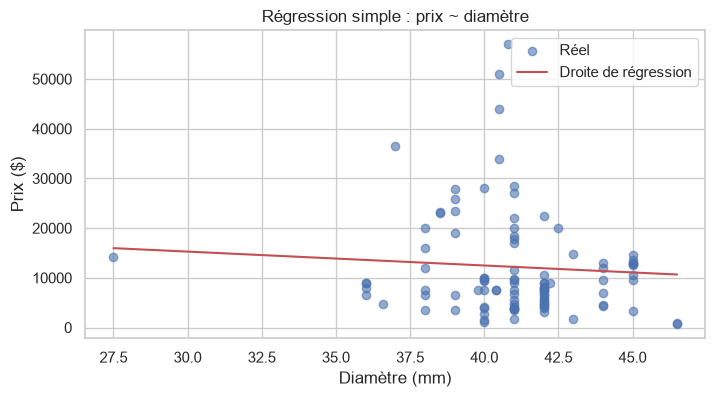

In [10]:
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
res = {}
def evaluer(nom, y_true, y_pred):
    res[nom] = {"R²": r2_score(y_true, y_pred), "RMSE": mean_squared_error(y_true, y_pred) ** 0.5, "MAE": mean_absolute_error(y_true, y_pred)}
    return res[nom]
lr_s = LinearRegression().fit(X_tr[["Case Diameter (mm)"]], yr_tr)
p_s = lr_s.predict(X_te[["Case Diameter (mm)"]])
print(evaluer("Régression simple", yr_te, p_s))
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(X_te["Case Diameter (mm)"], yr_te, alpha=.6, label="Réel")
xs = np.linspace(X_te["Case Diameter (mm)"].min(), X_te["Case Diameter (mm)"].max(), 50)
ax.plot(xs, lr_s.predict(pd.DataFrame({"Case Diameter (mm)": xs})), "r", label="Droite de régression")
ax.set_xlabel("Diamètre (mm)"); ax.set_ylabel("Prix ($)"); ax.legend(); ax.set_title("Régression simple : prix ~ diamètre")
plt.savefig("figs/06_reg_simple.png", dpi=150, bbox_inches="tight"); plt.show()

Le diamètre seul n'explique presque rien (R² proche de 0, voire négatif sur le test).

### 4.2 Régression linéaire multiple

{'R²': 0.7788085240197693, 'RMSE': 4786.464360079539, 'MAE': 2894.235698723875}


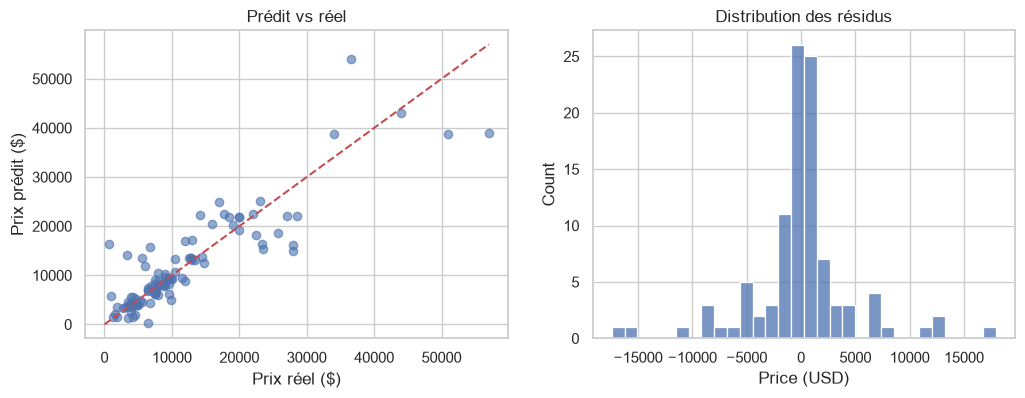

In [11]:
lr_m = LinearRegression().fit(X_tr, yr_tr)
p_m = lr_m.predict(X_te)
print(evaluer("Régression multiple", yr_te, p_m))
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].scatter(yr_te, p_m, alpha=.6); m = yr_te.max(); axs[0].plot([0, m], [0, m], "r--")
axs[0].set_xlabel("Prix réel ($)"); axs[0].set_ylabel("Prix prédit ($)"); axs[0].set_title("Prédit vs réel")
sns.histplot(yr_te - p_m, bins=30, ax=axs[1]); axs[1].set_title("Distribution des résidus")
plt.savefig("figs/07_reg_multiple.png", dpi=150, bbox_inches="tight"); plt.show()

### 4.3 Random Forest

{'R²': 0.8761540352516358, 'RMSE': 3581.5545195181394, 'MAE': 2187.8327453365446}


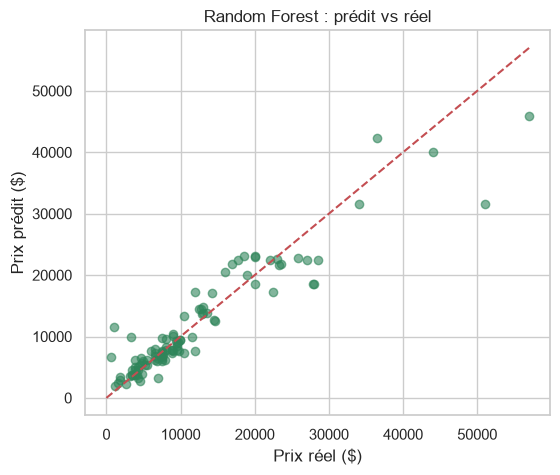

In [12]:
rf = RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1).fit(X_tr, yr_tr)
p_rf = rf.predict(X_te)
print(evaluer("Random Forest", yr_te, p_rf))
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(yr_te, p_rf, alpha=.6, color="#2f855a"); ax.plot([0, m], [0, m], "r--")
ax.set_xlabel("Prix réel ($)"); ax.set_ylabel("Prix prédit ($)"); ax.set_title("Random Forest : prédit vs réel")
plt.savefig("figs/08_rf.png", dpi=150, bbox_inches="tight"); plt.show()

### 4.4 Comparaison des modèles et variables importantes

,R²,RMSE,MAE
Régression simple,0.015,10099.081,7445.847
Régression multiple,0.779,4786.464,2894.236
Random Forest,0.876,3581.555,2187.833


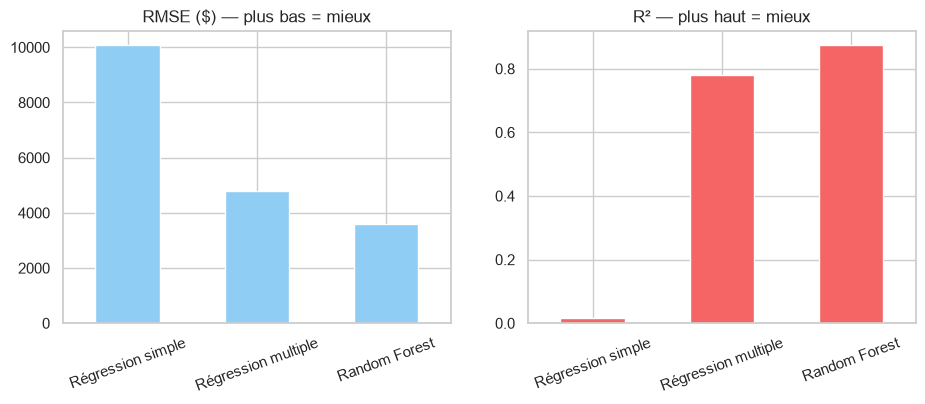

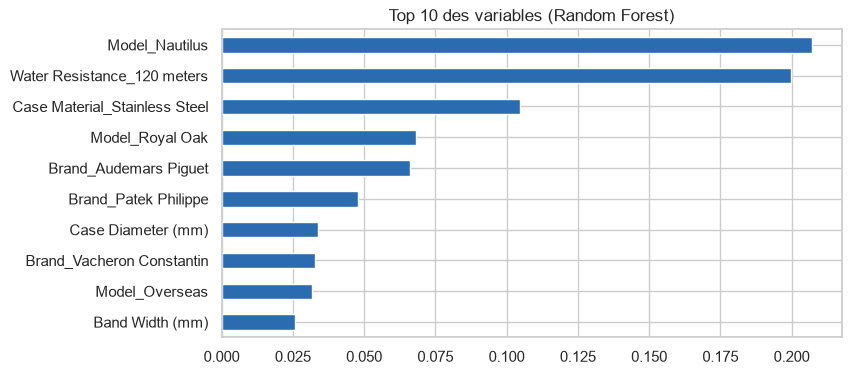

In [13]:
comp = pd.DataFrame(res).T.round(3); display(comp)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
comp["RMSE"].plot.bar(ax=axs[0], color="#90cdf4", title="RMSE ($) — plus bas = mieux")
comp["R²"].plot.bar(ax=axs[1], color="#f56565", title="R² — plus haut = mieux")
for a in axs: a.tick_params(axis="x", rotation=20)
plt.savefig("figs/09_comparaison.png", dpi=150, bbox_inches="tight"); plt.show()
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
fig, ax = plt.subplots(figsize=(8, 4)); imp[::-1].plot.barh(ax=ax, color="#2b6cb0")
ax.set_title("Top 10 des variables (Random Forest)")
plt.savefig("figs/10_importance.png", dpi=150, bbox_inches="tight"); plt.show()

### 4.5 Validation croisée (robustesse)
Un seul découpage train/test peut être chanceux : on vérifie le R² du Random Forest en validation croisée à 5 plis.

In [14]:
from sklearn.model_selection import cross_val_score, KFold
cv_r2 = cross_val_score(RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1), X, y_reg, cv=KFold(5, shuffle=True, random_state=SEED), scoring="r2")
print("R² par pli :", cv_r2.round(3), " moyenne :", cv_r2.mean().round(3), "±", cv_r2.std().round(3))

R² par pli : [0.769 0.842 0.877 0.816 0.807]  moyenne : 0.822 ± 0.036


## 5. Classification Accessible / Premium — régression logistique

Accuracy : 0.922  |  ROC-AUC : 0.962
              precision    recall  f1-score   support

  Accessible       0.89      0.96      0.92        51
     Premium       0.96      0.88      0.92        51

    accuracy                           0.92       102
   macro avg       0.92      0.92      0.92       102
weighted avg       0.92      0.92      0.92       102



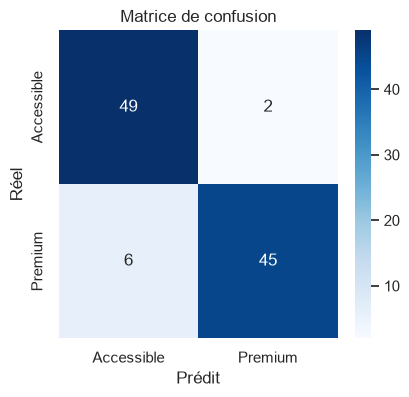

In [15]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, roc_auc_score
logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=1.0)).fit(X_tr, yc_tr)
pc = logit.predict(X_te); proba = logit.predict_proba(X_te)[:, 1]
print(f"Accuracy : {accuracy_score(yc_te, pc):.3f}  |  ROC-AUC : {roc_auc_score(yc_te, proba):.3f}")
print(classification_report(yc_te, pc, target_names=["Accessible", "Premium"]))
fig, ax = plt.subplots(figsize=(4.5, 4))
sns.heatmap(confusion_matrix(yc_te, pc), annot=True, fmt="d", cmap="Blues", ax=ax,
            xticklabels=["Accessible", "Premium"], yticklabels=["Accessible", "Premium"])
ax.set_xlabel("Prédit"); ax.set_ylabel("Réel"); ax.set_title("Matrice de confusion")
plt.savefig("figs/11_confusion.png", dpi=150, bbox_inches="tight"); plt.show()

## 6. Prédictions sur trois montres de référence
Prix prédit par le Random Forest (intervalle ± RMSE) et probabilité de classe par la régression logistique.

,Montre,Prix prédit ($),Intervalle bas,Intervalle haut,Classe,Probabilité de la classe
0,Rolex Submariner,8961,5379,12543,Premium,0.995
1,Omega Seamaster,6426,2845,10008,Accessible,0.991
2,Patek Philippe Nautilus,38250,34668,41831,Premium,0.996


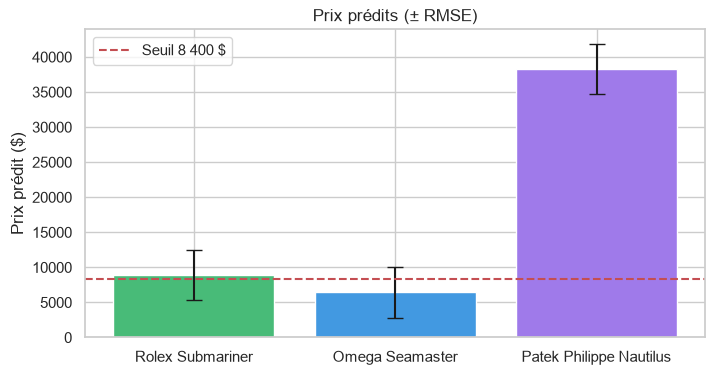

In [16]:
refs = {"Rolex Submariner": ("Rolex", "Submariner"), "Omega Seamaster": ("Omega", "Seamaster"), "Patek Philippe Nautilus": ("Patek Philippe", "Nautilus")}
rmse_rf = res["Random Forest"]["RMSE"]; rows = []
for nom, (b, mo) in refs.items():
    x = X[(df.Brand == b) & (df.Model == mo)].iloc[[0]]
    prix = rf.predict(x)[0]; pp = logit.predict_proba(x)[0, 1]
    rows.append({"Montre": nom, "Prix prédit ($)": round(prix), "Intervalle bas": round(prix - rmse_rf), "Intervalle haut": round(prix + rmse_rf),
                 "Classe": "Premium" if pp >= .5 else "Accessible", "Probabilité de la classe": round(max(pp, 1 - pp), 3)})
pred = pd.DataFrame(rows); display(pred)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(pred["Montre"], pred["Prix prédit ($)"], yerr=rmse_rf, capsize=6, color=["#48bb78", "#4299e1", "#9f7aea"])
ax.axhline(SEUIL, ls="--", color="r", label="Seuil 8 400 $"); ax.legend(); ax.set_ylabel("Prix prédit ($)")
ax.set_title("Prix prédits (± RMSE)")
plt.savefig("figs/12_predictions.png", dpi=150, bbox_inches="tight"); plt.show()

## 7. Conclusions
- **Random Forest** est le meilleur modèle de prix : il capte les effets non linéaires (marque × modèle × matériau) que la régression linéaire rate.
- La **régression simple** sur le diamètre est inutilisable : la taille ne fait pas le prix.
- La **régression logistique** classe correctement la grande majorité des montres en Accessible / Premium ; les erreurs se concentrent près du seuil de 8 400 \$.
- **Facteurs clés** : modèle et marque (Nautilus, Royal Oak, Audemars Piguet…), matériau du boîtier, étanchéité.
- **Limites** : 506 montres seulement, prix catalogue (pas de marché secondaire), modèles dupliqués dans le jeu → le test contient des références déjà vues, ce qui flatte les scores. Pistes : historique d'enchères, état, année.